# Modelado: reproduccion de referencias

Carlos Zambrano Figueroa | Grupo 11

Se reproducen regresion logistica y Random Forest con sus configuraciones historicas, y se agrega Dummy prior. Son comparaciones de desarrollo, no una seleccion final ni evaluacion de la reserva.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / 'src/train.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src/train.py').exists():
    raise RuntimeError('Ejecutar desde la raiz del repositorio o notebooks/')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src.train import run
from src.verify import verify
from src.baseline_report import run as create_report, FIGURES

report = run()
print(verify())
create_report()


Dummy_prior fold 1: F1=0.222222, coverage20=0.202643


Dummy_prior fold 2: F1=0.222222, coverage20=0.180617


Dummy_prior fold 3: F1=0.221803, coverage20=0.192982


Dummy_prior fold 4: F1=0.221803, coverage20=0.201754


Dummy_prior fold 5: F1=0.222013, coverage20=0.215859


...

RF_base fold 3: F1=0.540068, coverage20=0.407895


RF_base fold 4: F1=0.492490, coverage20=0.377193


RF_base fold 5: F1=0.498932, coverage20=0.396476


{'models': 3, 'oof_rows': 10617, 'folds_per_model': 5, 'verified': True, 'test_scored': False}


{'dataset_sha256': '3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae',
 'seed': 42,
 'labels': ['Dropout', 'Enrolled', 'Graduate'],
 'development_rows': 3539,
 'test_reserved_rows': 885,
 'test_scored': False,
 'oof_verified': True,
 'versions': {'python': '3.11.8',
  'sklearn': '1.6.1',
  'numpy': '1.26.4',
  'pandas': '2.2.3'},
 'aggregation': 'Unweighted mean and sample SD across five historical folds; SD is not a CI.',
 'ranking': 'Top ceil(0.2*n) within each fold; stable ties in historical development order.',
 'dummy_note': 'Prior predicts majority class; tied ranking is arbitrary, not a learned ranking.',
 'random_ranking_expected_coverage': 0.20062170865997012,
 'summary': {'Dummy_prior': {'train_f1_macro': 0.2220128107399078,
   'train_f1_macro_sd': 5.238001838586604e-05,
   'train_accuracy': 0.49929358574459126,
   'train_accuracy_sd': 0.0001766160719702644,
   'train_log_loss': 1.0198391184894056,
   'train_log_loss_sd': 7.9609118745513e-05,
   'train_recall_

## Configuraciones y protocolo

Cada modelo se ajusta en los cinco folds historicos. Todo el preprocesamiento queda dentro del pipeline. LR: C=1, class_weight=balanced, max_iter=3000. RF: 200 arboles, min_samples_leaf=3, max_depth=None, max_features=sqrt y class_weight=balanced. Semilla 42.

Dummy prior predice la clase mayoritaria y probabilidades iguales a las frecuencias de entrenamiento. No aprende un ranking: sus empates se resuelven por el orden historico.


In [2]:
table = pd.DataFrame(report['summary']).T
columns = ['train_f1_macro', 'val_f1_macro', 'val_f1_macro_sd',
           'gap_f1', 'val_accuracy', 'val_recall_dropout', 'val_recall20']
display(table[columns])
print('Cobertura esperada de seleccion aleatoria:', report['random_ranking_expected_coverage'])
print('Advertencias de entrenamiento:', [w for fold in report['folds'] for w in fold['warnings']])


,train_f1_macro,val_f1_macro,val_f1_macro_sd,gap_f1,val_accuracy,val_recall_dropout,val_recall20
Dummy_prior,0.222013,0.222013,0.000209,7.405109e-08,0.499294,0.000000,0.198771
LR_base,0.574855,0.515839,0.018358,5.901571e-02,0.549584,0.524113,0.397527
RF_base,0.780568,0.519956,0.022413,2.606127e-01,0.582363,0.574248,0.391379


Cobertura esperada de seleccion aleatoria: 0.20062170865997012
Advertencias de entrenamiento: []


## Media de folds frente a resultados agrupados

Las tablas principales usan medias no ponderadas de los cinco folds. La desviacion estandar no es un intervalo de confianza. Las matrices de confusion agregan 3.539 predicciones fuera de fold; las metricas derivadas de esa matriz no sustituyen la media de folds.


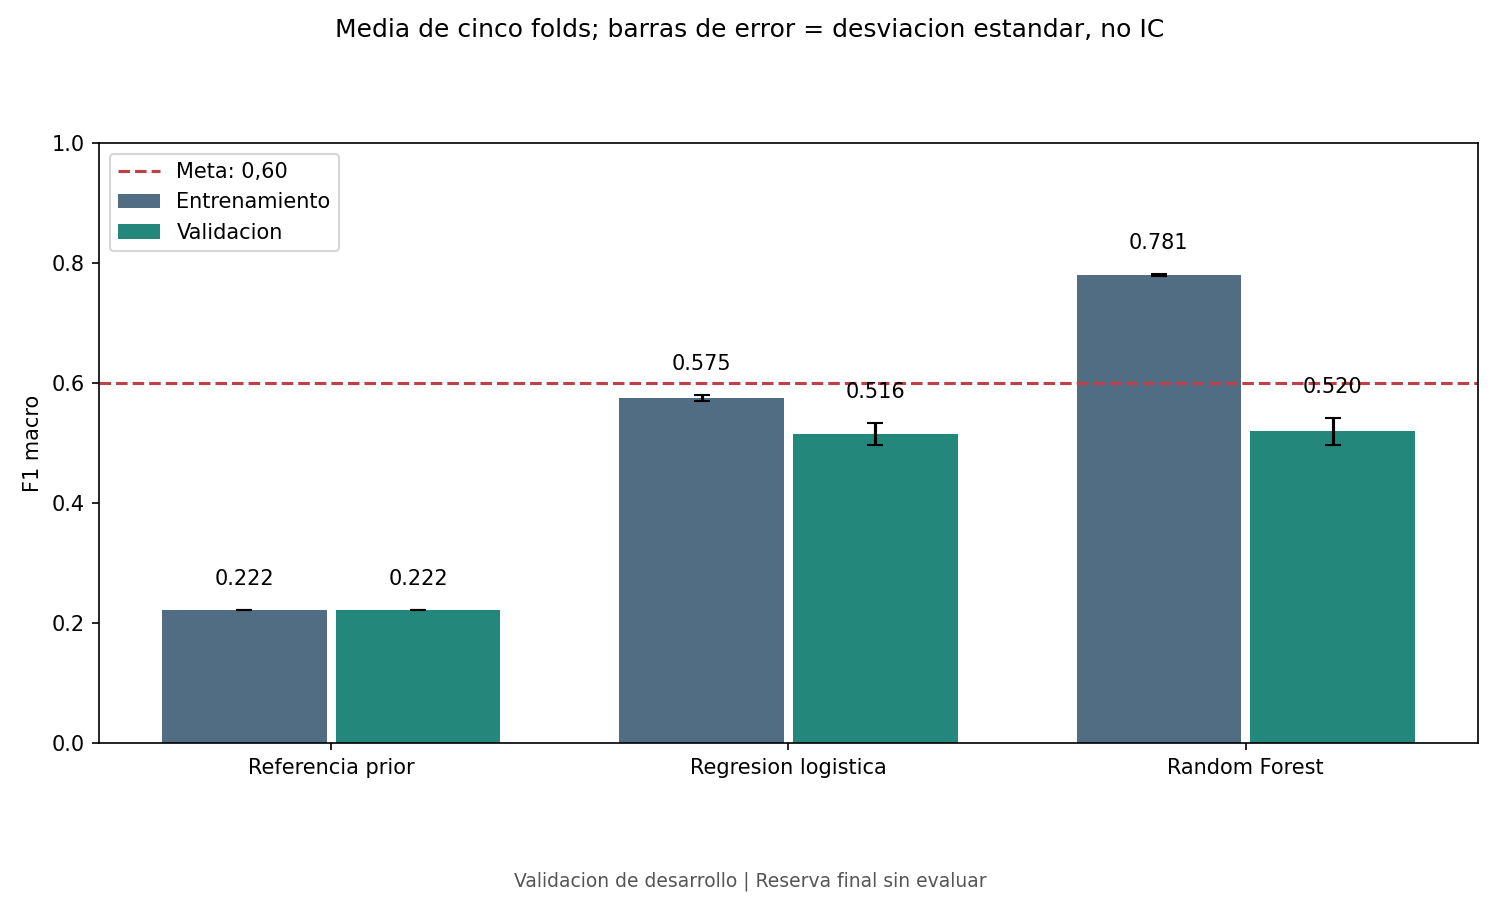

In [3]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[0])))


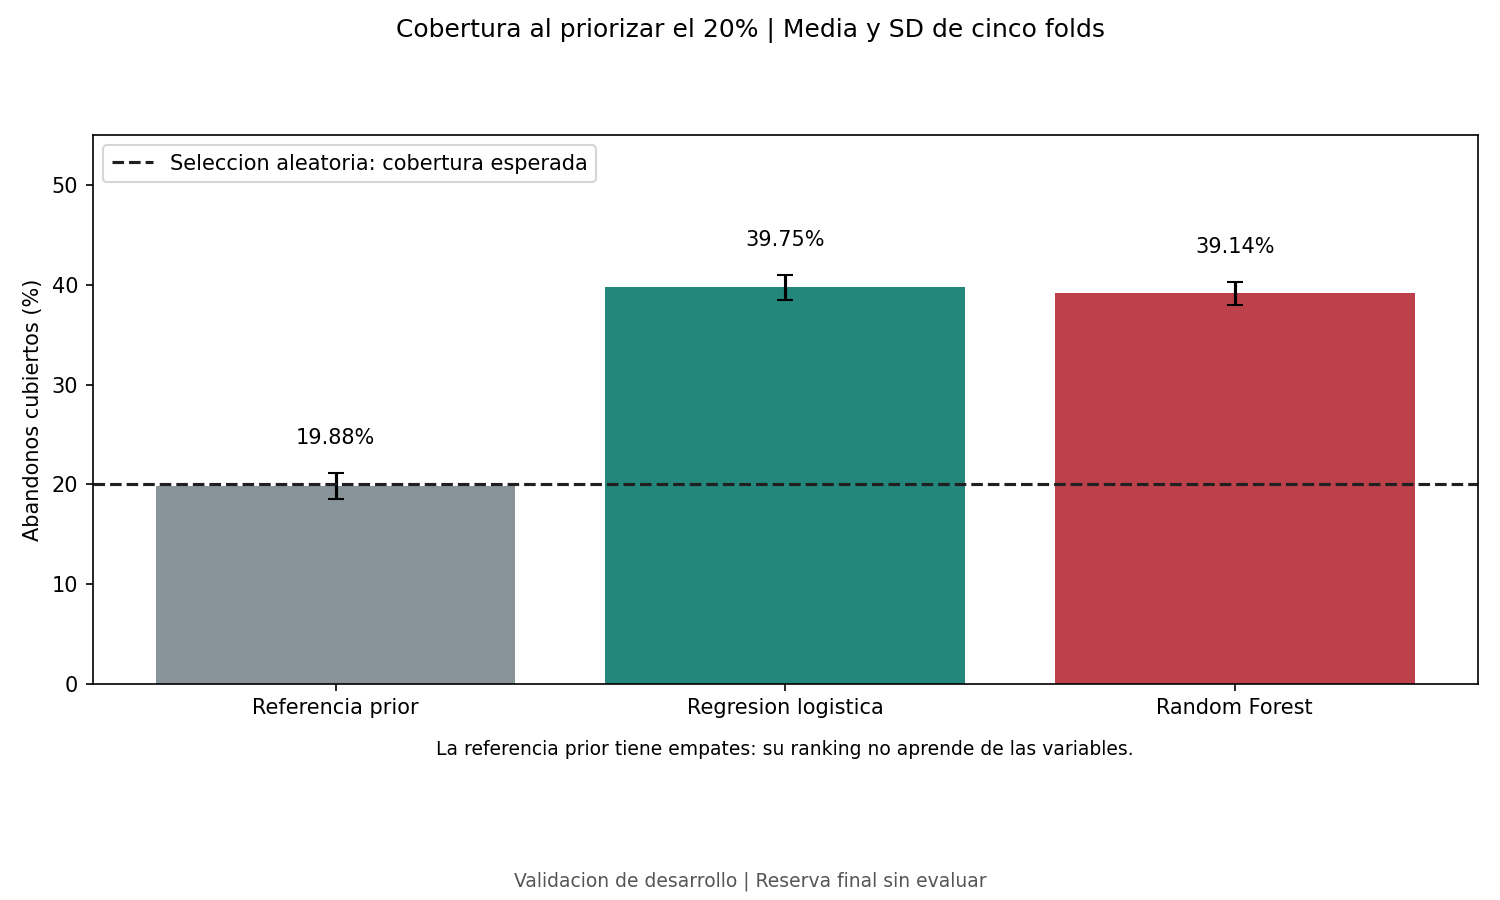

In [4]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[1])))


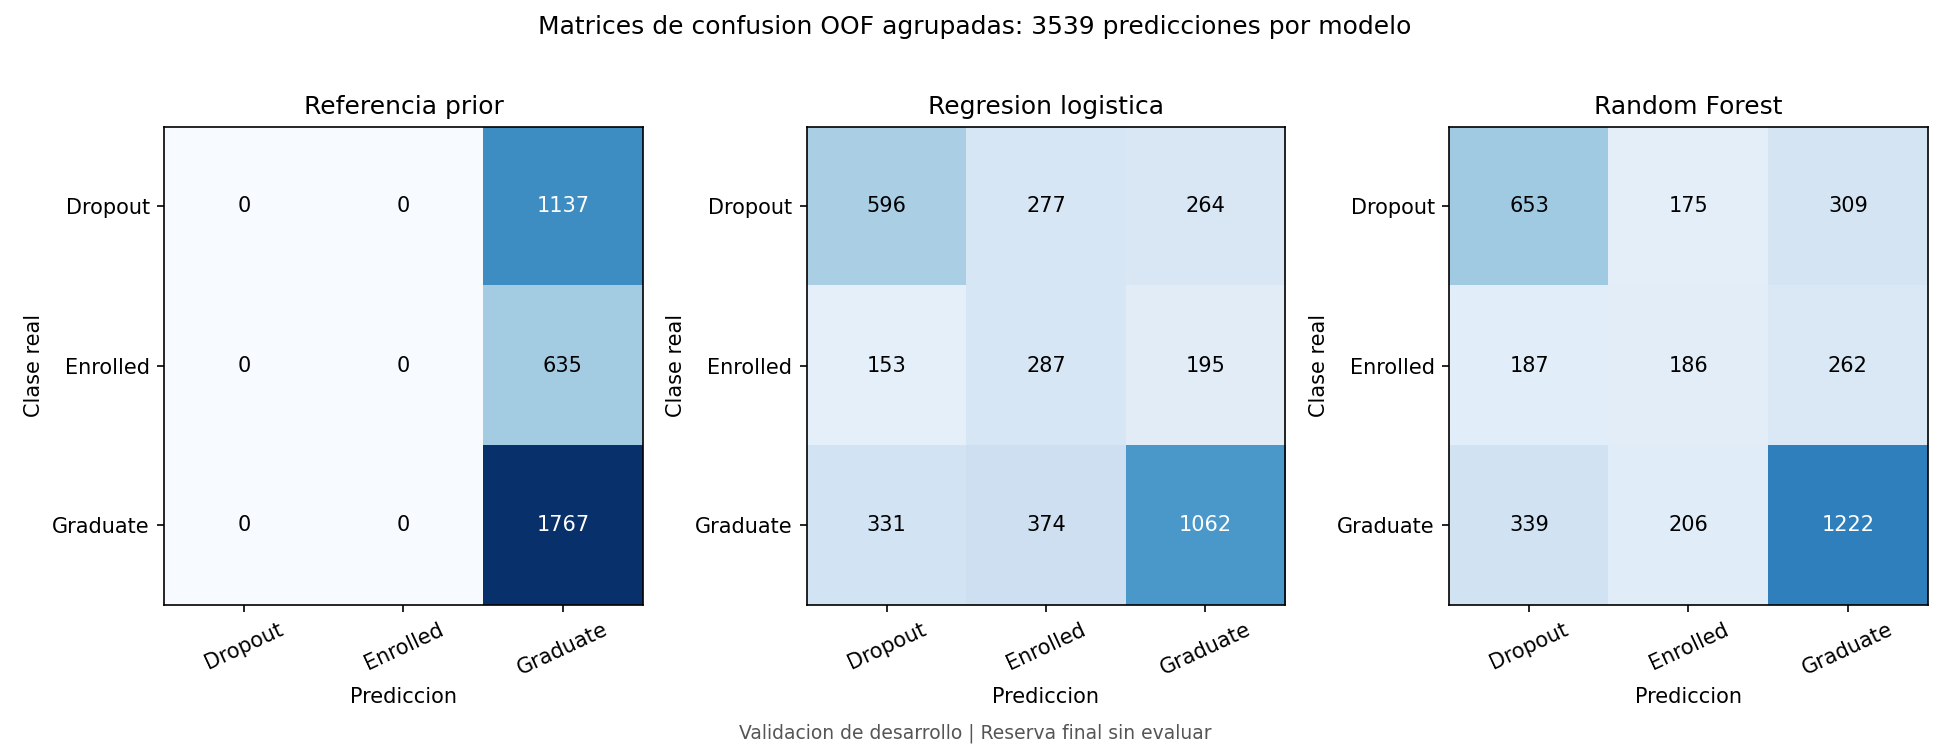

In [5]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[2])))


## Cobertura y limites

La cobertura mide abandonos detectados dentro de una lista de ceil(20% de n) estudiantes por fold, divididos por el total de abandonos reales de ese fold. No equivale a precision. Se conserva el orden de desempate historico. La seleccion uniforme aleatoria cubriria en promedio k/n, aproximadamente 20%; no se presenta esa expectativa como una simulacion ejecutada.

La lista priorizada no constituye una decision de elegibilidad. El prototipo se limita a apoyar revision humana y acompanamiento voluntario.


## Diagnostico que orienta la siguiente fase

La regresion tiene rendimiento limitado incluso en entrenamiento y una brecha menor, consistente con sesgo alto o senal limitada. Random Forest presenta sobreajuste. Las siguientes estrategias deben abordar estos problemas: limitar complejidad del bosque y explorar representaciones o modelos no lineales regularizados. No basta con aplicar mas regularizacion a la regresion.

Ningun modelo alcanza F1 macro 0,60. La pequena ventaja de RF en F1 no demuestra superioridad estadistica y su cobertura es menor. El modelo final no se elige en este notebook. La reserva, calibracion, equidad y validez local siguen pendientes.

Resultados y definiciones: `results/reports/baseline_report.md`. Recalculo: `python -m src.verify`.
